In [ ]:
import os
import sys
import networkx as nx

module_path = os.path.abspath(os.path.join('..'))

if module_path not in sys.path:
    sys.path.append(module_path)

# Notes

In [3]:
from pathlib import Path

from iso639 import Language
from matplotlib import pyplot as plt
from matplotlib import ticker
import numpy as np
import polars as pl

OUT_PATH: Path = Path("../out")
DATA_PATH: Path = Path("../data/processed/words")
COLOR: str = "darkslategrey"

langs = pl.read_parquet(OUT_PATH / "languages.parquet")
langs_scraped = [f.stem for f in DATA_PATH.glob("*.parquet")]
words = pl.read_parquet(OUT_PATH / "words.parquet")
cols = set(langs.columns).intersection(words.columns)
words = words.join(langs, on=list(cols)).with_columns(pl.col("word").str.len_chars().alias("n_char"))
sylls = pl.read_parquet(OUT_PATH / "syllables.parquet").join(langs, on=list(cols)).with_columns(n_phon = pl.col("syll").str.len_chars())



def iso639_p3_to_name(p3: str):
    try:
        lang = Language.from_part3(p3)
        return str(lang.name)
    except (LookupError, ValueError, AttributeError):
        return


## Outline

* Speech is made of hierarchically organised, discrete linguistic units (e.g., phonemes, syllables, words, phrases). Syllables are a privileged linguistic unit, particularly during early language acquisition: newborns preferentially chunk the speech signal into syllable-sized units. This is remarkable, given they have accumulated a relatively limited linguistic experience. The mechanisms underlying syllable identification are still unclear. 
* There is some evidence that, at birth, humans are sensitivity to certain constraints to syllabic structure. One of them is the Sonority Sequencing Principle (SSP). [Explain sonority and SSP]. For instance, Gómez et al. showed in newborns that hearing SSP-following syllables elicits different brain haemodynamic responses compared to SSP-violating syllables. Such early bias toward certain syllabic structures would provide humans with an available mechanism to detect syllables in the continuous speech stream in the earliest stages of language acquisition.
* The SSP has been long claimed to be a linguistic universal, on the grounds of SSP-following syllables being less marked than SSP-violating syllables across most languages. The universality of the SSP would place it as one of the few cues for speech segmentation present from birth to *all* humans, before more experience-dependent (e.g., statistical learning over syllables) or language-specific constraints to sound sequences (e.g., phonotactics) are available.
* The universal status of the SSP is a matter of debate, as violations of the SSP are common across languages: exceptions to the SSP can be found in most languages.
* The aim of the present paper is to provide empirical estimates of the prevalence of the SSP in a fairly representative sample of languages.

## Languages

### Number of available languages

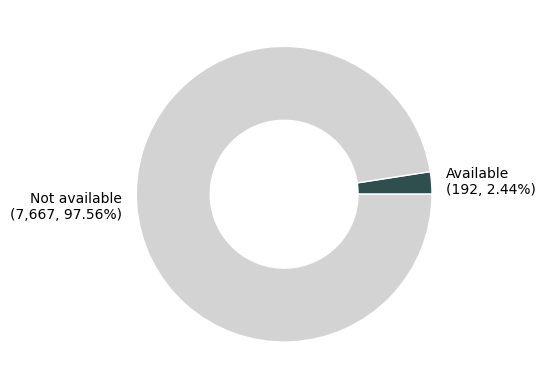

In [4]:
data = (
    langs.with_columns(
        status=pl.when(pl.col("iso639p3code").is_in(words["iso639p3code"].to_list()))
        .then(pl.lit("Available"))
        .otherwise(pl.lit("Not available"))
    )
    .group_by("status")
    .len("n")
)

values = data["n"]
labels = [f"{s}\n({n:,}, {n / sum(values):.2%})" for s, n in data.iter_rows()]

fig, ax = plt.subplots(1, 1)
p = ax.pie(
    values,
    labels=labels,
    radius=1,
    wedgeprops=dict(width=0.5, edgecolor="w"),
    colors=[COLOR, "lightgrey"],
)


### Language families

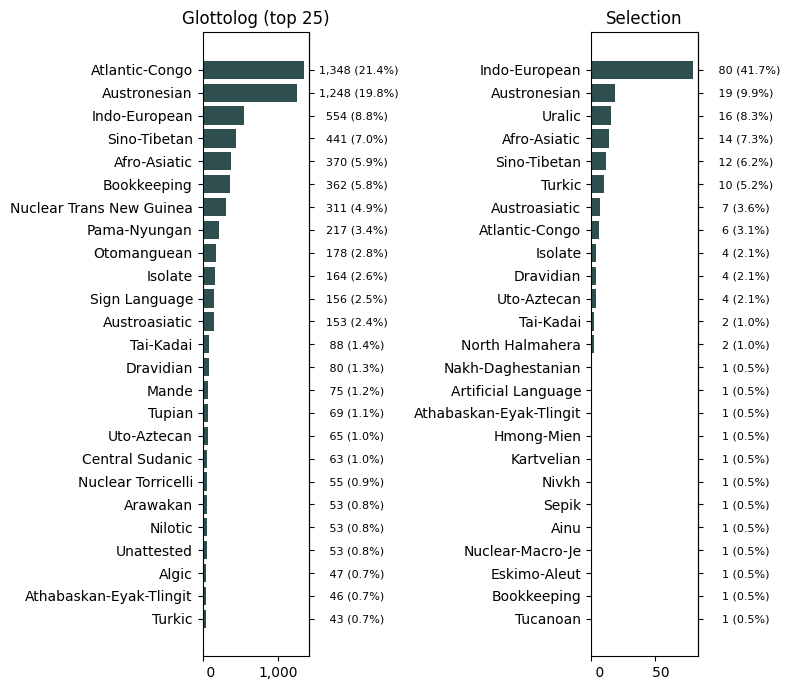

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 7))
n_fams = len(words.unique("family_id"))
for d, t, ax in zip([langs, words], [f"Glottolog (top {n_fams})", "Selection"], axes):
    d = d.unique("iso639p3code").group_by("family_id").len("n").sort("n")
    if len(d) > 100:
        d = d.top_k(k=n_fams, by="n").sort("n")

    p = ax.barh(d["family_id"], d["n"], color=COLOR)
    
    ticks = ax.get_yticks()
    labels = [f"{n:5,d} ({n / sum(d['n']):.1%})" for n in d["n"]]
    ax2 = ax.secondary_yaxis('right')
    ax2.set_yticks(ticks)
    ax2.set_yticklabels(labels)
    ax2.tick_params(axis="y", labelsize=8)
    ax.set_title(t)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))

fig.tight_layout()


Text(-0.15, 1, 'Most languages')

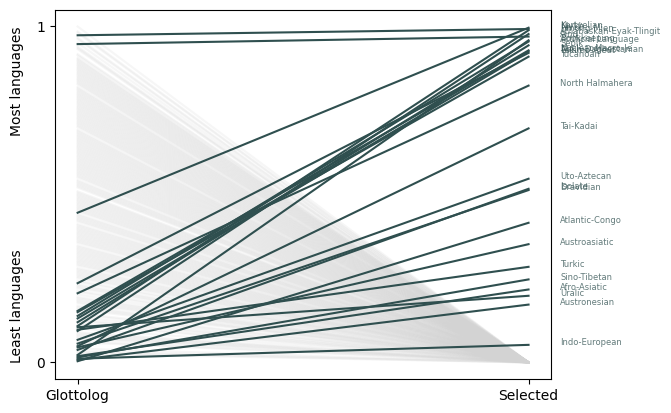

In [6]:
cols = ["iso639p3code", "family_id"]
data = [
    langs.select(cols).with_columns(source=pl.repeat("Glottolog", len(langs))),
    words.select(cols)
    .unique("iso639p3code")
    .with_columns(source=pl.repeat("Selected", pl.len())),
]
data = (
    pl.concat(data)
    .group_by(["source", "family_id"])
    .len("n")
    .with_columns(
        rank=pl.col("n")
        .over("source")
        .rank("ordinal", descending=True)
        .cast(pl.Float64)
        / pl.len()
    )
    .sort("rank")
    .pivot(index="family_id", on="source", values="rank")
    .rename(lambda x: x.lower())
    .fill_null(0)
    .with_columns((pl.col("glottolog") - pl.col("selected")).alias("diff"))
    .with_columns(
        diff=(pl.col("diff") - pl.col("diff").min())
        / (pl.col("diff").max() - pl.col("diff").min())
    )
    .sort("diff", descending=True)
)

fig, ax = plt.subplots(1, 1)
for f, g, s, d in data.iter_rows(named=False):
    ax.plot(
        ["Glottolog", "Selected"],
        [g, s],
        c="lightgrey" if s == 0 else COLOR,
        alpha=0.2 if s == 0 else 1,
    )
    if s != 0:
        ax.text(1.07, s, f, ha="left", fontsize=6, alpha=0.75, color=COLOR)
ax.set_yticks([0, 1])
ax.text(x=-0.15, y=0, s="Least languages", rotation=90, va="bottom")
ax.text(x=-0.15, y=1, s="Most languages", rotation=90, va="top")


## Words

### Number of words per language

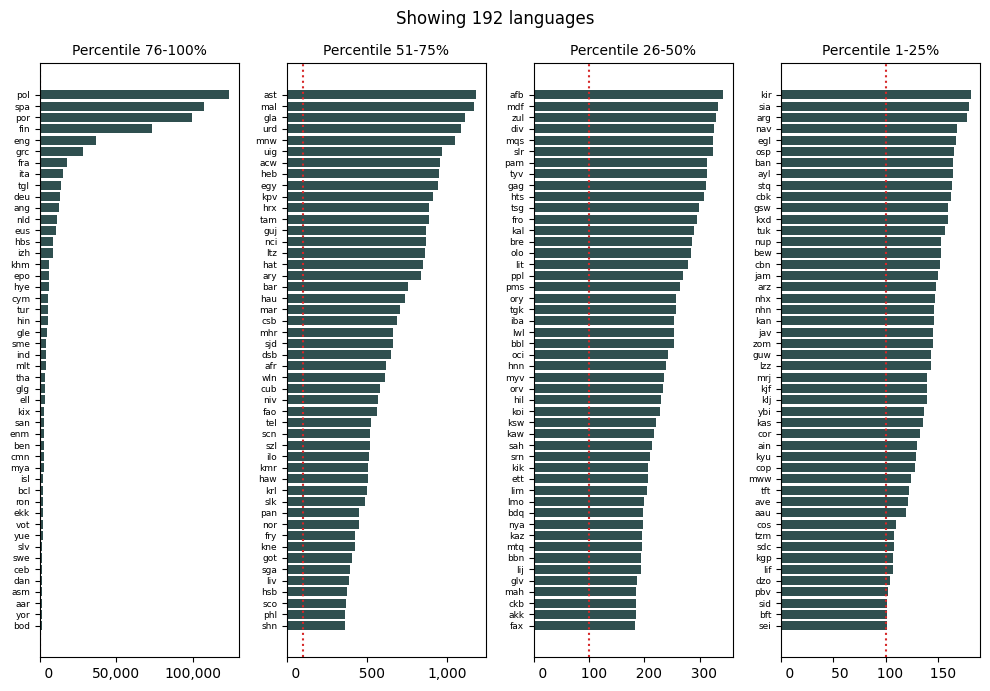

In [7]:
data = (
    words.group_by("iso639p3code")
    .len("n")
    .with_columns(
        qtile=pl.col("n").qcut(
            [0.25, 0.50, 0.75], labels=["1-25%", "26-50%", "51-75%", "76-100%"]
        )
    )
).sort("qtile", descending=True)

n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    lang, n, q = d.sort("n").iter_columns()
    ax = axes[i]
    ax.barh(lang, n, color=COLOR)
    ax.set_title(f"Percentile {q[0]}", fontsize=10)
    
    ax.tick_params(axis="y", labelsize=6.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))
    ax.axvline(100, linestyle="dotted", color="tab:red")
fig.suptitle(f"Showing {len(data)} languages")
fig.tight_layout()

### Word lengths

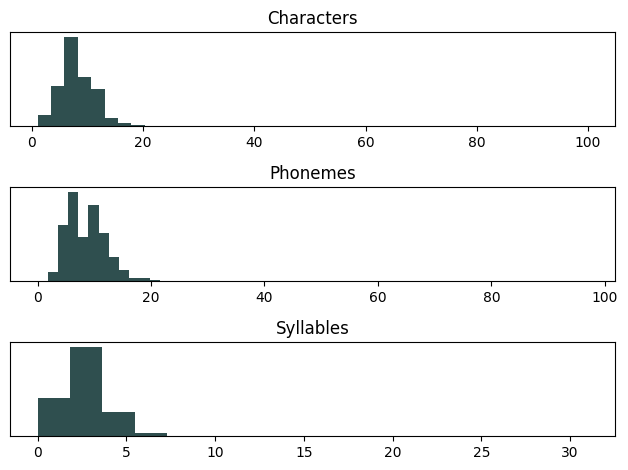

In [8]:
vars = {"char": "Characters", "phon": "Phonemes", "syll": "Syllables"}

fig, axes = plt.subplots(len(vars), 1)
for i, (var, label) in enumerate(vars.items()):
    x=words[f"n_{var}"]
    ax = axes[i]
    ax.hist(x, bins=len(set(x)), color=COLOR)
    ax.set_title(label)
    ax.set_yticks([])
fig.tight_layout()


### By number of characters

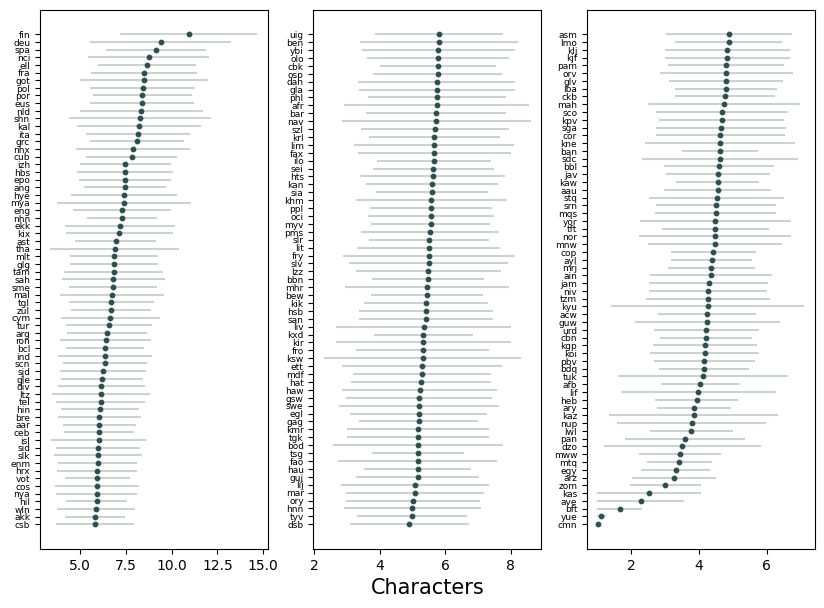

In [9]:
data = (
    words.group_by(["iso639p3code"])
    .agg(mean=pl.col("n_char").mean(), std=pl.col("n_char").std())
    .with_columns(
        qtile=pl.col("mean").qcut(
            [0.33, 0.66], labels=["Top 3rd", "Mid 3rd", "Bottom 3rd"]
        )
    )
    .sort(["qtile", "mean"])
)

n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    limit = 1
    dist_to_limit = d["mean"] - limit
    yerr_clipped = np.minimum(d["std"], dist_to_limit)

    ax = axes[i]
    ax.errorbar(
        d["mean"],
        d["iso639p3code"],
        xerr=yerr_clipped,
        c=COLOR,
        alpha=1 / 4,
        linestyle="None",
    )
    if i==n_qtiles//2:
        ax.set_xlabel("Characters", fontsize=15)
    ax.scatter(d["mean"], d["iso639p3code"], s=10, c=COLOR)
    ax.tick_params(axis="y", labelsize=6.5)

#### By number of phonemes

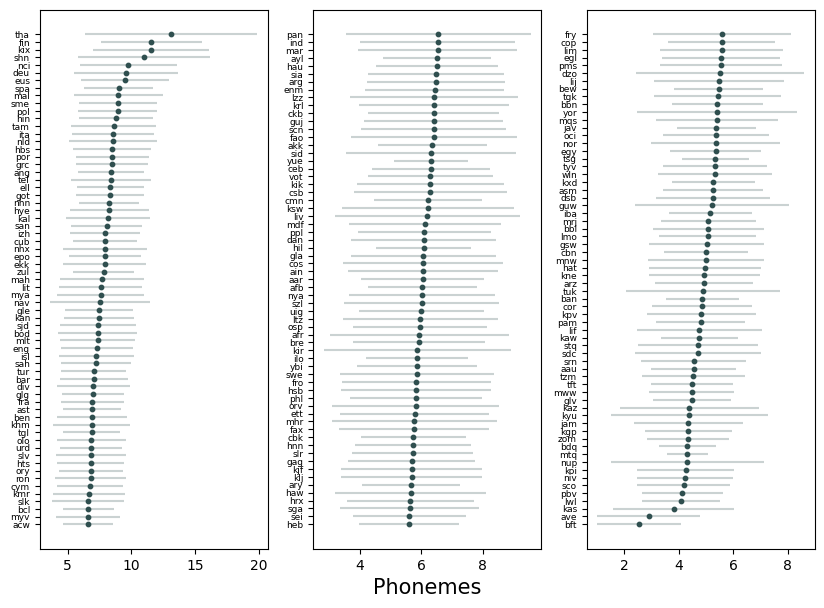

In [10]:
data = (
    words.group_by(["iso639p3code"])
    .agg(mean=pl.col("n_phon").mean(), std=pl.col("n_phon").std())
    .with_columns(
        qtile=pl.col("mean").qcut(
            [0.33, 0.66], labels=["Top 3rd", "Mid 3rd", "Bottom 3rd"]
        )
    )
    .sort(["qtile", "mean"])
)

n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    limit = 1
    dist_to_limit = d["mean"] - limit
    yerr_clipped = np.minimum(d["std"], dist_to_limit)

    ax = axes[i]
    ax.errorbar(
        d["mean"],
        d["iso639p3code"],
        xerr=yerr_clipped,
        c=COLOR,
        alpha=1 / 4,
        linestyle="None",
    )
    if i==n_qtiles//2:
        ax.set_xlabel("Phonemes", fontsize=15)
    ax.scatter(d["mean"], d["iso639p3code"], s=10, c=COLOR)
    ax.tick_params(axis="y", labelsize=6.5)


### By number of syllables

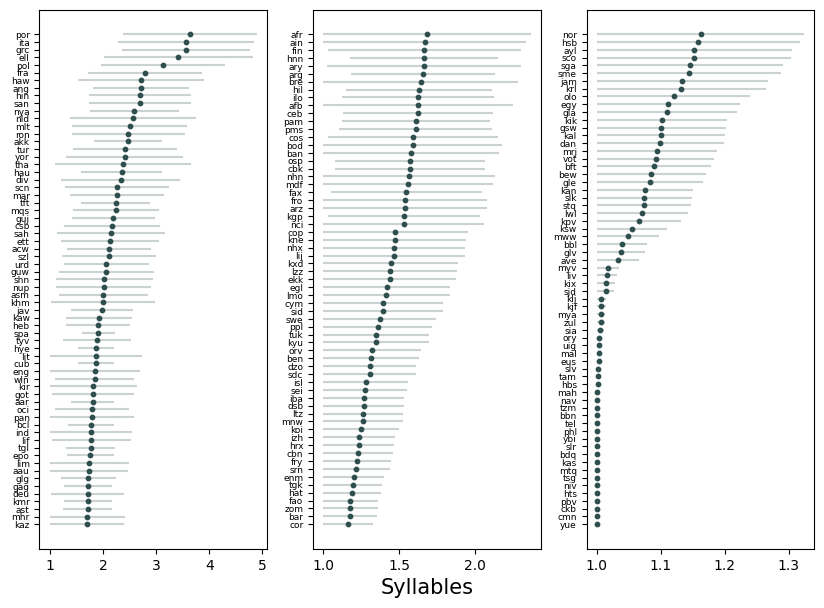

In [11]:
data = (
    words.group_by(["iso639p3code"])
    .agg(mean=pl.col("n_syll").mean(), std=pl.col("n_syll").std())
    .with_columns(
        qtile=pl.col("mean").qcut(
            [0.33, 0.66], labels=["Top 3rd", "Mid 3rd", "Bottom 3rd"]
        )
    )
    .sort(["qtile", "mean"])
)

# TODO: compare chars, phons and sylls from each language individually
n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    limit = 1
    dist_to_limit = d["mean"] - limit
    yerr_clipped = np.minimum(d["std"], dist_to_limit)

    ax = axes[i]
    ax.errorbar(
        d["mean"],
        d["iso639p3code"],
        xerr=yerr_clipped,
        c=COLOR,
        alpha=1 / 4,
        linestyle="None",
    )
    if i==n_qtiles//2:
        ax.set_xlabel("Syllables", fontsize=15)
    ax.scatter(d["mean"], d["iso639p3code"], s=10, c=COLOR)
    ax.tick_params(axis="y", labelsize=6.5)


### Word length against number of words

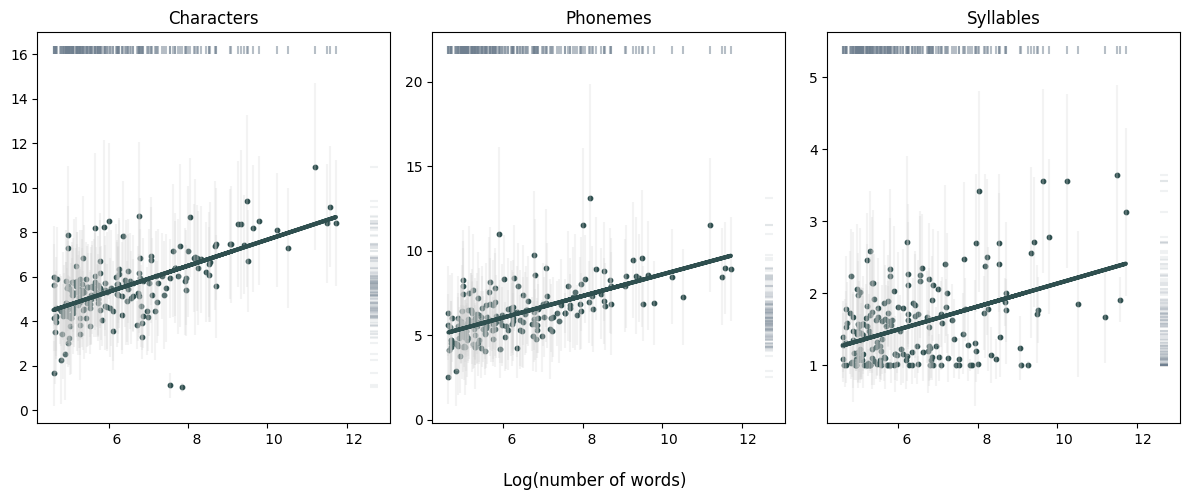

In [12]:
data = (
    words
    .group_by(["iso639p3code"])
    .agg(
        mean_phonemes=pl.col("n_phon").mean(),
        std_phonemes=pl.col("n_phon").std(),
        mean_characters=pl.col("n_char").mean(),
        std_characters=pl.col("n_char").std(),
        mean_syllables=pl.col("n_syll").mean(),
        std_syllables=pl.col("n_syll").std(),
        n=pl.len().log(),
    )
)

units = ["characters", "phonemes", "syllables"]
fig, (axes) = plt.subplots(1, len(units), figsize=(12, 5))

for i, var in enumerate(units):
    x = data["n"]
    coef = np.polyfit(x.to_list(), data[f"mean_{var}"].to_list(), 1)
    fit = np.poly1d(coef)
    ax = axes[i]
    ax.errorbar(
        x,
        data[f"mean_{var}"],
        yerr=data[f"std_{var}"],
        c="lightgrey",
        alpha=1 / 4,
        linestyle="None",
    )
    ax.plot(x, fit(x), lw=3, c=COLOR)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))
    ax.scatter(x, data[f"mean_{var}"], s=10, c=COLOR)
    ax.set_title(f"{var.title()}")
    _, ymax = ax.get_ylim()
    ax.scatter(data["n"], [ymax + (ymax*0.05)] * len(data), marker="|", c="slategrey", alpha= 0.5)

    _, xmax = ax.get_xlim()
    ax.scatter([xmax + (xmax * 0.05)]*len(data), data[f"mean_{var}"],  marker="_", c="slategrey", alpha = 0.1)
fig.supxlabel("Log(number of words)")
fig.tight_layout()

## Lexical frequencies

### Available lexical frequencies

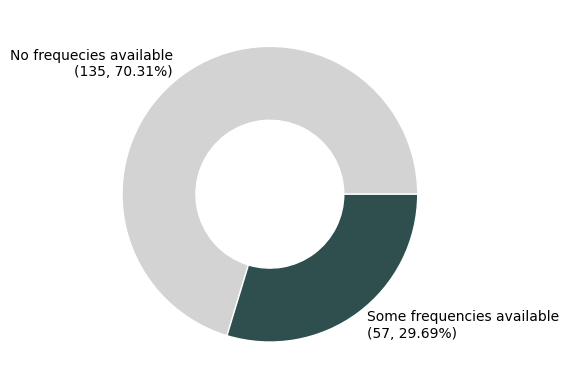

In [267]:
data = (
    words.select(["iso639p3code", "freq"])
    .group_by("iso639p3code")
    .agg(pl.col("freq").is_null().sum().alias("n_missing"), n=pl.len())
    .with_columns(prop_missing=pl.col("n_missing") / pl.col("n")).sort("prop_missing", descending=True)
    .with_columns(availability =pl.when(pl.col("prop_missing")==1).then(pl.lit("No frequecies available")).otherwise(pl.lit("Some frequencies available")))
    .group_by("availability")
    .len("n")
)

values = data["n"]
labels = [f"{s}\n({n:,}, {n / sum(values):.2%})" for s, n in data.iter_rows()]

fig, ax = plt.subplots(1, 1)
p = ax.pie(
    values,
    labels=labels,
    radius=1,
    wedgeprops=dict(width=0.5, edgecolor="w"),
    colors=["lightgrey", COLOR],
)

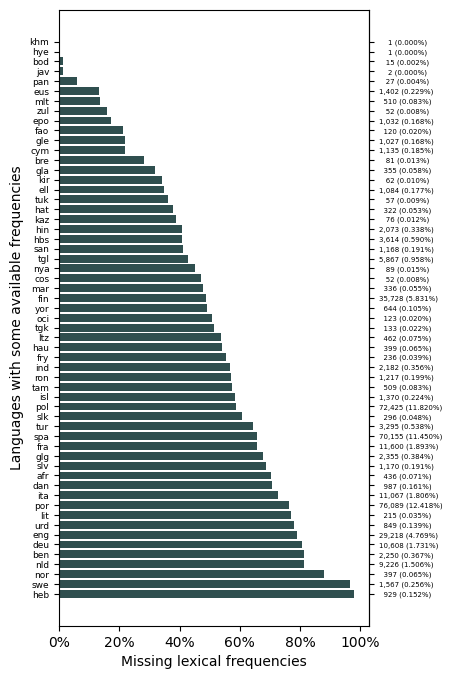

In [268]:
data = (
    words.select(["iso639p3code", "freq"])
    .group_by("iso639p3code")
    .agg(pl.col("freq").is_not_null().sum().alias("n_obs"), n=pl.len())
    .with_columns(prop_obs=pl.col("n_obs") / pl.col("n")).sort("prop_obs", descending=True)
    .filter(pl.col("prop_obs")!=0)
)

fig, ax = plt.subplots(1, 1, figsize=(4, 8))
ax.barh(data["iso639p3code"], data["prop_obs"], color=COLOR)
ax.tick_params(axis="y", labelsize=6.5)
ax.set_ylabel("Languages with some available frequencies")
ax.set_xlabel("Missing lexical frequencies")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))

ticks = ax.get_yticks()
labels = [f"{n:5,d} ({n / sum(data['n']):.3%})" for n in data["n_obs"]]
ax2 = ax.secondary_yaxis('right')
ax2.set_yticks(ticks)
ax2.set_yticklabels(labels, ha="left")
ax2.tick_params(axis="y", labelsize=5)


### Proportion of observed frequencies by number of observations

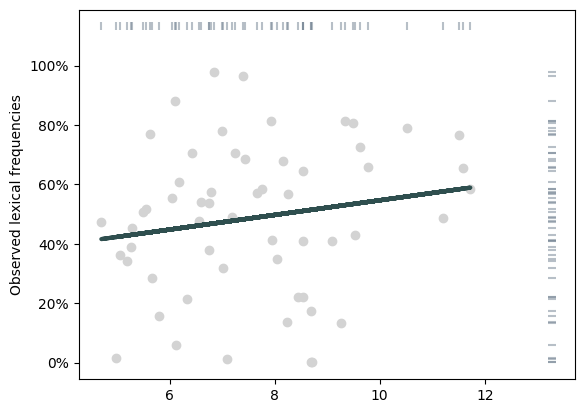

In [269]:
data = (
    words.select(["iso639p3code", "freq"])
    .group_by("iso639p3code")
    .agg(pl.col("freq").is_not_null().sum().alias("n_obs"), n=pl.len())
    .with_columns(prop_obs=pl.col("n_obs") / pl.col("n"), n = pl.col("n").log()).sort("prop_obs", descending=True)
    .filter(pl.col("prop_obs")!=0)
)

fig, ax = plt.subplots(1, 1)
ax.scatter(data["n"],  data["prop_obs"], c="lightgrey")
coef = np.polyfit(data["n"].to_list(), data["prop_obs"].to_list(), 1)
fit = np.poly1d(coef)
ax.plot(data["n"], fit(data["n"]), lw=3, c=COLOR)
ax.set_ylabel("Observed lexical frequencies")
ax.set_label("Log(Number of words)")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))

_, ymax = ax.get_ylim()
ax.scatter(data["n"], [ymax + (ymax*0.1)] * len(data), marker="|", c="slategrey", alpha= 0.5)

_, xmax = ax.get_xlim()
ax.scatter([xmax + (xmax * 0.1)]*len(data), data["prop_obs"],  marker="_", c="slategrey", alpha = 0.5)



### Distribution of lexical frequencies

### Distribution of lexical frequencies by language

Text(0.5, 0, 'Lexical frequency (Zipf)')

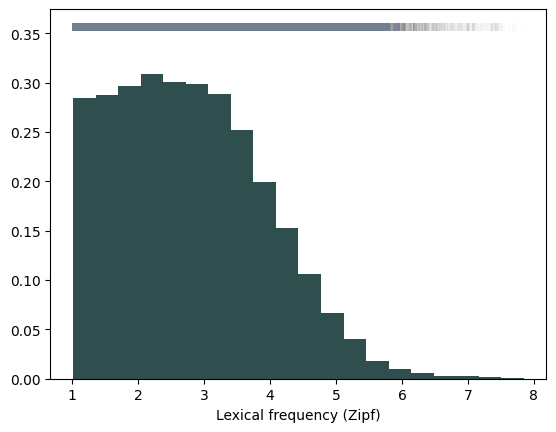

In [270]:
data = words.select(["iso639p3code", "word", "freq"]).drop_nulls()

fig, ax = plt.subplots(1, 1)
p = ax.hist(data["freq"], density=True, histtype="stepfilled", bins=20, lw=3, color=COLOR)
_, ymax = ax.get_ylim()
ax.scatter(data["freq"], [ymax + (ymax*0.1)] * len(data), marker="|", c="slategrey", alpha = 0.005)

ax.set_xlabel("Lexical frequency (Zipf)")

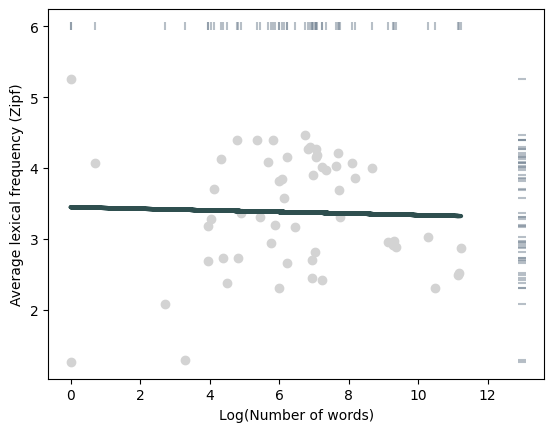

In [271]:
data = words.select(["iso639p3code", "word", "freq"]).drop_nulls().group_by("iso639p3code").agg(pl.col("freq").mean(), n=pl.len().log())

fig, ax = plt.subplots(1, 1)
ax.scatter(data["n"], data["freq"], color="lightgrey")
coef = np.polyfit(data["n"].to_list(), data["freq"].to_list(), 1)
fit = np.poly1d(coef)
ax.plot(data["n"], fit(data["n"]), lw=3, c=COLOR)
ax.set_xlabel("Log(Number of words)")
ax.set_ylabel("Average lexical frequency (Zipf)")

_, ymax = ax.get_ylim()
ax.scatter(data["n"], [ymax + (ymax*0.1)] * len(data), marker="|", c="slategrey", alpha=0.5)

_, xmax = ax.get_xlim()
ax.scatter([xmax + (xmax * 0.1)]*len(data), data["freq"],  marker="_", c="slategrey", alpha=0.5)



## Syllables

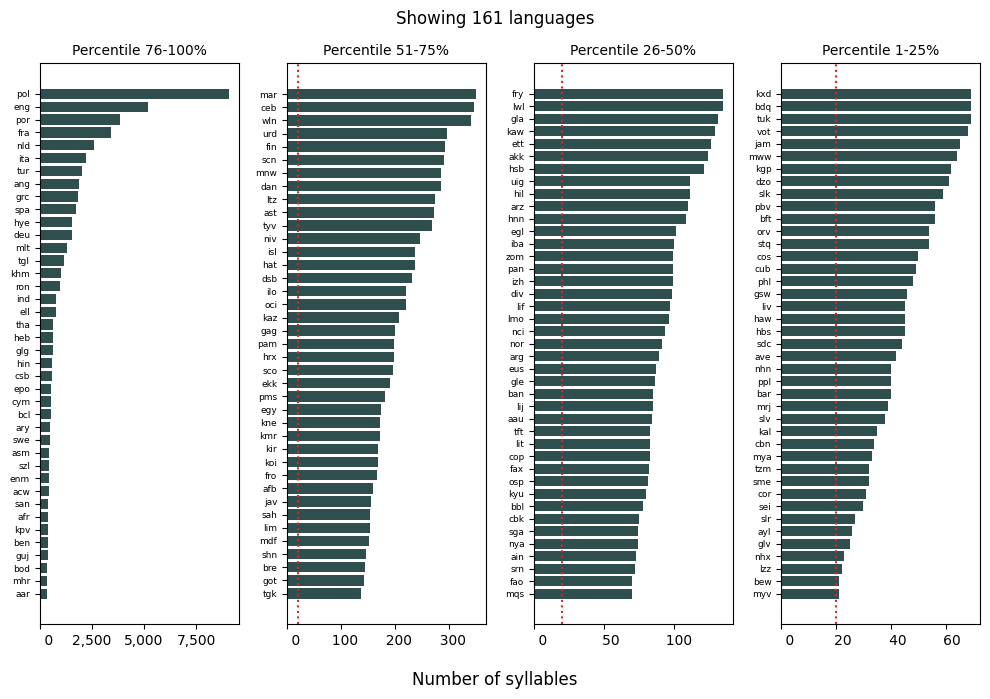

In [272]:
data = (
    sylls.group_by("iso639p3code")
    .len("n")
    .with_columns(
        qtile=pl.col("n").qcut(
            [0.25, 0.50, 0.75], labels=["1-25%", "26-50%", "51-75%", "76-100%"]
        )
    )
).sort("qtile", descending=True)

n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    lang, n, q = d.sort("n").iter_columns()
    ax = axes[i]
    ax.barh(lang, n, color=COLOR)
    ax.set_title(f"Percentile {q[0]}", fontsize=10)
    
    ax.tick_params(axis="y", labelsize=6.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))
    ax.axvline(20, linestyle="dotted", color="tab:red")
fig.suptitle(f"Showing {len(data)} languages")
fig.supxlabel("Number of syllables")
fig.tight_layout()

### Syllable lengths

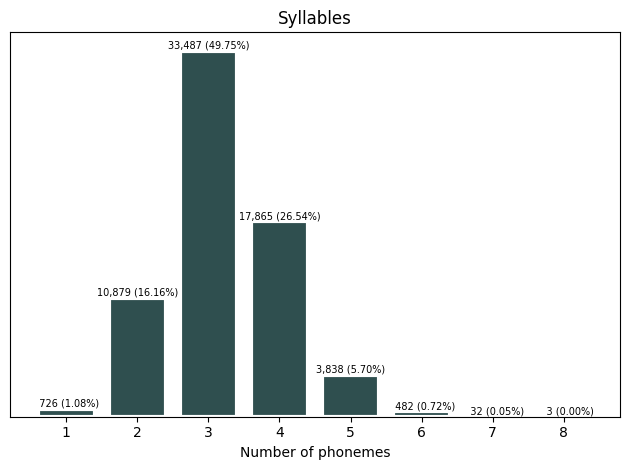

In [273]:
fig, ax = plt.subplots(1, 1)
labels, values =sylls["n_phon"].value_counts().iter_columns()
value_labels = [f"{v:5,d} ({v / sum(values):.2%})" for v in values]
p = ax.bar(labels, values, color=COLOR, edgecolor="white", linewidth=3)
ax.bar_label(p, value_labels, fontsize=7)
ax.set_title(label)
ax.set_yticks([])
ax.set_xlabel("Number of phonemes")
fig.tight_layout()

### Syllabic structures

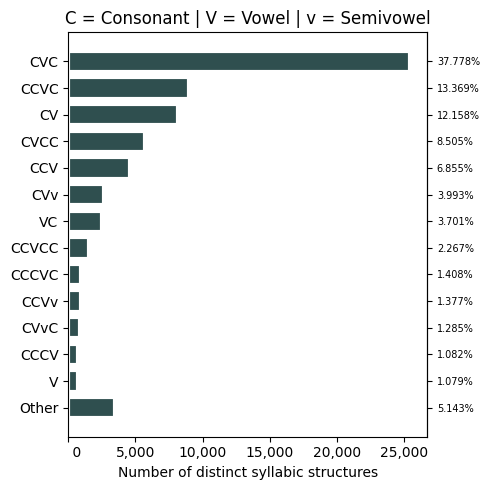

In [274]:
data = (
    sylls.group_by("struct")
    .len("n")
    .sort("n")
    .with_columns(
        struct=pl.when(pl.col("n") < (0.01 * len(sylls))).then(pl.lit("Other")).otherwise("struct"),
    )
    .group_by("struct")
    .agg(n=pl.col("n").sum())
    .sort("n")
    .with_columns(
        prop=pl.col("n") / pl.col("n").sum(),
        order=pl.when(pl.col("struct") == "Other").then(1).otherwise(0),
    )
    .sort(["order", "prop"], descending=[True, False])
)


fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.barh(data["struct"], data["n"], color=COLOR, edgecolor="white", linewidth=3)
ax.set_title("C = Consonant | V = Vowel | v = Semivowel")
ax.set_xlabel("Number of distinct syllabic structures")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))

ticks = ax.get_yticks()
labels = [f"{n:.3%}" for n in data["prop"]]
ax2 = ax.secondary_yaxis("right")
ax2.set_yticks(ticks)
ax2.set_yticklabels(labels, ha="left")
ax2.tick_params(axis="y", labelsize=7)

fig.tight_layout()

### Sonority sequencing principle

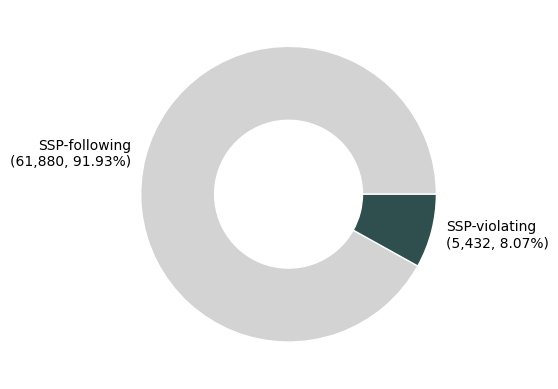

In [275]:
data = sylls.select(["iso639p3code", "is_ssp"]).get_column("is_ssp").value_counts()
values = data["count"]
labels = [
    f"{'SSP-following' if s else 'SSP-violating'}\n({n:,}, {n / sum(values):.2%})"
    for s, n in data.iter_rows()
]

fig, ax = plt.subplots(1, 1)
p = ax.pie(
    values,
    labels=labels,
    radius=1,
    wedgeprops=dict(width=0.5, edgecolor="w"),
    colors=["lightgrey", COLOR],
)

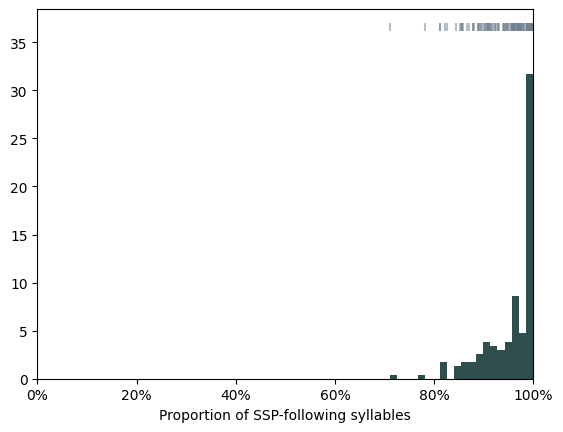

In [276]:
data = sylls.group_by("iso639p3code").agg(pl.col("is_ssp").mean())

fig, ax = plt.subplots(1, 1)
p = ax.hist(data["is_ssp"], density=True, histtype="stepfilled", bins=20, lw=3, color=COLOR)
_, ymax = ax.get_ylim()
ax.scatter(data["is_ssp"], [ymax + (ymax*0.1)] * len(data), marker="|", c="slategrey", alpha = 0.5)

ax.set_xlabel("Proportion of SSP-following syllables")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))

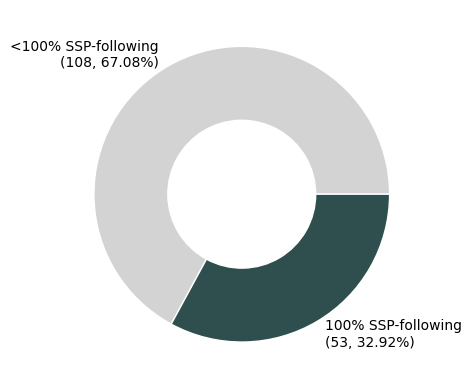

In [277]:
data = (
    (
        sylls.group_by("iso639p3code")
        .agg(pl.col("is_ssp").mean(), n=pl.len())
        .sort("is_ssp", descending=False)
        .with_columns(is_ssp=pl.when(pl.col("is_ssp") == 1).then(1).otherwise(0))
    )
    .get_column("is_ssp")
    .value_counts()
)

values = data["count"]
labels = [
    f"{'100% SSP-following' if s else '<100% SSP-following'}\n({n:,}, {n / sum(values):.2%})"
    for s, n in data.iter_rows()
]

fig, ax = plt.subplots(1, 1)
p = ax.pie(
    values,
    labels=labels,
    radius=1,
    wedgeprops=dict(width=0.5, edgecolor="w"),
    colors=["lightgrey", COLOR],
)

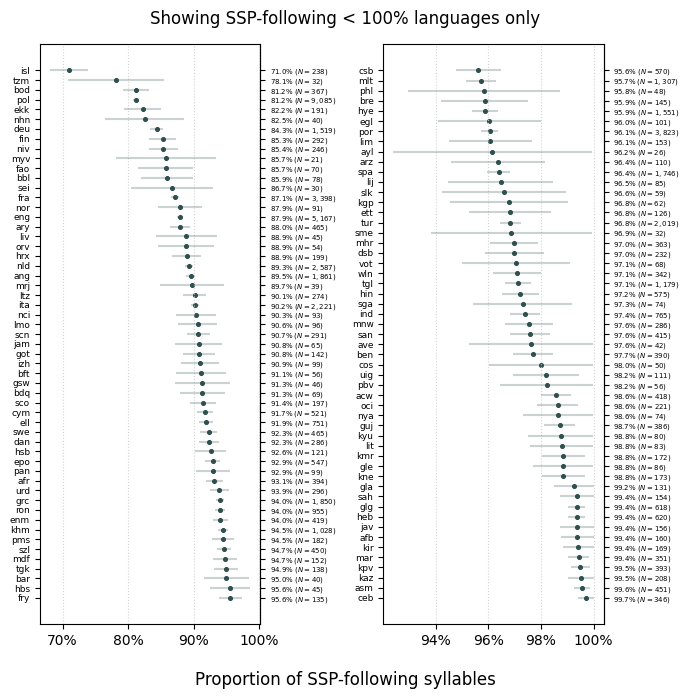

In [278]:
data = (
    sylls.group_by("iso639p3code")
    .agg(pl.col("is_ssp").mean(), n=pl.len())
    .filter(pl.col("is_ssp") != 1)
    .with_columns(se=((pl.col("is_ssp") * (1 - pl.col("is_ssp"))) / pl.col("n")).sqrt())
    .with_columns(
        qtile=pl.col("is_ssp").qcut([0.5], labels=["Bottom half", "Top half"])
    )
    .sort(["qtile", "is_ssp"], descending=[False, True])
    .partition_by("qtile", as_dict=True)
)


fig, axes = plt.subplots(1, len(data), figsize=(7, 7))
for i, (k, d) in enumerate(data.items()):
    ax = axes[i]
    dist_to_limit = d["is_ssp"] - 1
    yerr_clipped = np.maximum(d["se"], dist_to_limit)
    
    ax.errorbar(
        d["is_ssp"],
        d["iso639p3code"],
        xerr=yerr_clipped,
        c=COLOR,
        alpha=1 / 4,
        linestyle="None",
    )
    ax.scatter(d["is_ssp"], d["iso639p3code"], c=COLOR, s=7)

    ax.tick_params(axis="y", labelsize=6.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))
    ax.xaxis.grid(True, color="lightgrey", linestyle=":")

    ticks = ax.get_yticks()
    labels = [f"{p:.1%} ($N={n:5,d}$)" for p, n in zip(d["is_ssp"], d["n"])]
    ax2 = ax.secondary_yaxis("right")
    ax2.set_yticks(ticks)
    ax2.set_yticklabels(labels, ha="left")
    ax2.tick_params(axis="y", labelsize=5)

fig.suptitle("Showing SSP-following < 100% languages only")
fig.supxlabel("Proportion of SSP-following syllables")
fig.tight_layout()

List of languages with 100% SSP prevalence:

In [279]:
data = (
    sylls.group_by("iso639p3code")
    .agg(pl.col("is_ssp").mean(), n=pl.len())
    .filter(pl.col("is_ssp")==1)
)
data

iso639p3code,is_ssp,n
str,f64,u32
"""stq""",1.0,54
"""lwl""",1.0,135
"""lzz""",1.0,22
"""shn""",1.0,147
"""zom""",1.0,99
…,…,…
"""srn""",1.0,72
"""hil""",1.0,111
"""akk""",1.0,124


### SSP by number of observations

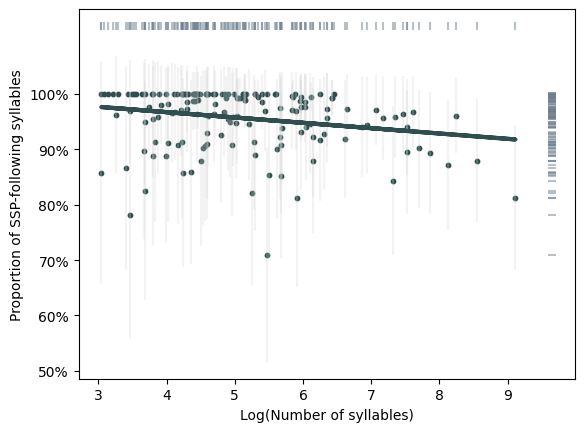

In [280]:
data = (
    sylls.group_by(["iso639p3code"])
    .agg(pl.col("is_ssp").mean(), n=pl.len().log())
    .with_columns(se=((pl.col("is_ssp") * (1 - pl.col("is_ssp"))) / pl.col("n")).sqrt())
)


fig, ax = plt.subplots(1, 1)
ax.scatter(data["n"], data["is_ssp"], color=COLOR, s=10)
dist_to_limit = data["is_ssp"] - 1
yerr_clipped = np.maximum(data["se"], dist_to_limit)
ax.errorbar(
    data["n"],
    data["is_ssp"],
    yerr=yerr_clipped,
    c="lightgrey",
    alpha=1 / 4,
    linestyle="None",
)

coef = np.polyfit(data["n"].to_list(), data["is_ssp"].to_list(), 1)
fit = np.poly1d(coef)
ax.plot(data["n"], fit(data["n"]), lw=3, c=COLOR)
ax.set_xlabel("Log(Number of syllables)")
ax.set_ylabel("Proportion of SSP-following syllables")

_, ymax = ax.get_ylim()
ax.scatter(
    data["n"], [ymax + (ymax * 0.025)] * len(data), marker="|", c="slategrey", alpha=0.5
)

_, xmax = ax.get_xlim()
ax.scatter(
    [xmax + (xmax * 0.025)] * len(data),
    data["is_ssp"],
    marker="_",
    c="slategrey",
    alpha=0.5,
)

ticks = np.linspace(0.5, 1, 6)
ax.set_yticks(ticks)
ax.set_yticklabels([f"{t:.0%}" for t in ticks])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))


## SSP and frequency

Text(0.5, 0.98, 'Ranked lexical frequency (Zipf)')

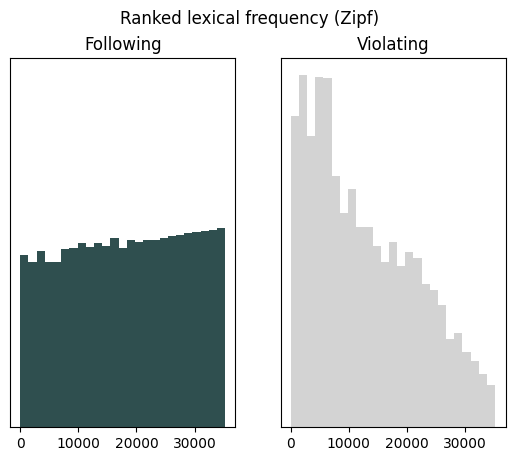

In [514]:
data = (
    sylls.select(["iso639p3code", "syll", "freq", "is_ssp"])
    .filter(pl.col("freq") != 0)
    .drop_nulls()
    .sort("is_ssp", descending=True)
    .with_columns(rank=pl.col("freq").rank())
)

colors = {True: COLOR, False: "lightgrey"}
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True)
for i, (k, d) in enumerate(data.partition_by("is_ssp", as_dict=True).items()):
    ax = axes[i]
    zorder = 0 if k[0] else 0
    ax.hist(
        d["rank"], bins=25, zorder=zorder, color=colors[k[0]], density=True, histtype="stepfilled"
    )
    ax.set_title("Following" if k[0] else "Violating")
    ax.set_yticklabels([])
    ax.set_yticks([])
fig.suptitle("Ranked lexical frequency (Zipf)")

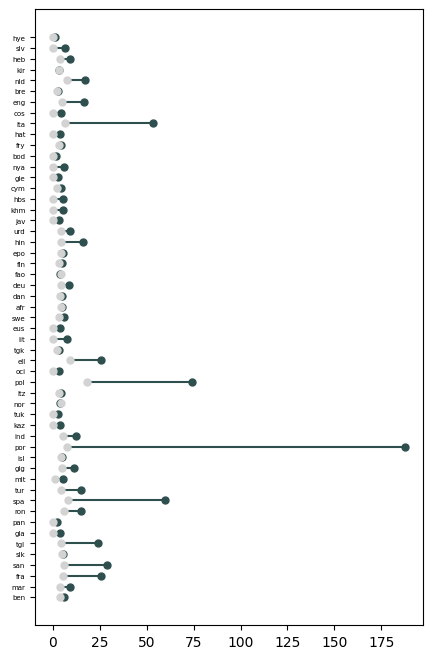

In [479]:
data = (
    sylls.select(["iso639p3code", "syll", "freq", "is_ssp"])
    .filter(pl.col("freq") != 0)
    .drop_nulls()
    .group_by(["iso639p3code", "is_ssp"])
    .agg(pl.col("freq").mean())
    .pivot(on="is_ssp", index=["iso639p3code"], values="freq").fill_null(0)
    .unpivot(index="iso639p3code",on=["true", "false"], variable_name="is_ssp", value_name="freq")
    .with_columns(pl.col("is_ssp")=="true")
)

data_ssp = data.filter(pl.col("is_ssp"))
data_no_ssp=data.filter(~pl.col("is_ssp"))

colors = {True: COLOR, False: "lightgrey"}
fig, ax = plt.subplots(1, 1, figsize=(5, 8))
ax.hlines(y=data_ssp["iso639p3code"], xmin=data_ssp["freq"], xmax = data_no_ssp["freq"], colors=[COLOR if a > b else "lightgrey" for a, b in zip(data_ssp["freq"], data_no_ssp["freq"])])

for k, d in data.partition_by("is_ssp", as_dict=True).items():
    is_ssp = k[0]
    label = "Following" if is_ssp else "Violating"
    zorder = 0 if is_ssp else 1
    ax.scatter(d["freq"], d["iso639p3code"], c=colors[is_ssp], s=25, zorder=10)
    ax.tick_params(axis="y", labelsize=5)
# fig.legend()


## The causal structure of the research question

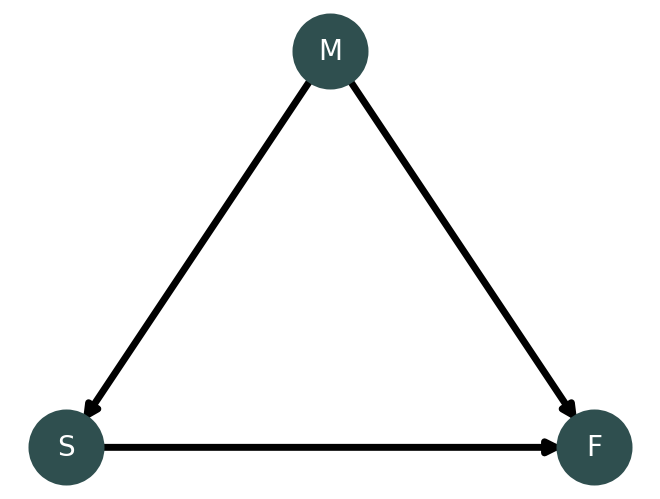

In [ ]:
# Create a Directed Graph (DiGraph)
G = nx.DiGraph()

# Add nodes
G.add_node("M")
G.add_node("S")
G.add_node("F")

# Add directed edges
G.add_edge("M", "S")
G.add_edge("M", "F")
G.add_edge("S", "F")

# Define positions for the nodes to ensure a clear layout
# (A at top, B on left bottom, C on right bottom)
pos = {"M": (0, 0.30), "S": (-0.15, 0), "F": (0.15, 0)}

# Draw the graph
# node_color='orange' sets the nodes to the requested color
# with_labels=True displays the node names
# arrowsize=20 makes the arrows visible and clear
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=COLOR,
    linewidths=10,
    node_size=2000,
    width=5,
    edge_color="k",
    font_size=20,
    font_color="white",
    arrowsize=20,
)

# Display the plot
plt.show()
